# Audio Preprocessing & Voiceprint Verification Model
**Formative 2 – Umucyo 3 (Audio)**

This notebook:
1. Loads every group member's recordings ("Yes, approve" and "Confirm transaction")
2. Plots a waveform and spectrogram for each member
3. Applies augmentations (pitch shift, time stretch, background noise)
4. Extracts audio features (MFCCs, spectral roll-off, energy) into `audio_features.csv`
5. Trains and evaluates a voiceprint verification model (accuracy, F1-score, loss)
6. Tests it on authorized and unauthorized voices and saves the model for integration


## 1. Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
AUDIO_DIR = "/content/drive/MyDrive/Audio"
OUTPUT_DIR = "/content/drive/MyDrive/audio_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(sorted(os.listdir(AUDIO_DIR)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['Allan_approve.wav', 'Allan_confirm.wav', 'David_approve.wav', 'David_confirm.wav', 'Nazira_approve.wav', 'Nazira_confirm.wav', 'Shamila_approve.wav', 'Shamila_confirm.wav', 'unknown_approve.wav', 'unknown_confirm.wav']


In [ ]:
import glob, subprocess, warnings
import numpy as np
import pandas as pd
import librosa, librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             log_loss, classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
np.random.seed(42)

SR = 22050                                     # sample rate used for every file
UNAUTHORIZED_NAMES = {"unknown"}               # file prefix for the outsider's recording
print("Libraries loaded ✅")

Libraries loaded ✅


## 2. Load the recordings
Each file name is split into the member's name (the label) and the phrase.

In [ ]:
records = []
for f in sorted(glob.glob(os.path.join(AUDIO_DIR, "*.wav"))):
    stem = os.path.splitext(os.path.basename(f))[0]      # "Nazira_approve"
    parts = stem.lower().split("_")                      # ["nazira", "approve"]
    records.append({"file": f, "member": parts[0], "phrase": "_".join(parts[1:])})

meta = pd.DataFrame(records)
train_meta = meta[~meta.member.isin(UNAUTHORIZED_NAMES)].reset_index(drop=True)
unauth_meta = meta[meta.member.isin(UNAUTHORIZED_NAMES)].reset_index(drop=True)

print("Recordings per member:")
print(train_meta.groupby("member").size())
print("\nUnauthorized recordings:", len(unauth_meta))
meta

Recordings per member:
member
allan      2
david      2
nazira     2
shamila    2
dtype: int64

Unauthorized recordings: 2


,file,member,phrase
0,/content/drive/MyDrive/Audio/Allan_approve.wav,allan,approve
1,/content/drive/MyDrive/Audio/Allan_confirm.wav,allan,confirm
2,/content/drive/MyDrive/Audio/David_approve.wav,david,approve
3,/content/drive/MyDrive/Audio/David_confirm.wav,david,confirm
4,/content/drive/MyDrive/Audio/Nazira_approve.wav,nazira,approve
5,/content/drive/MyDrive/Audio/Nazira_confirm.wav,nazira,confirm
6,/content/drive/MyDrive/Audio/Shamila_approve.wav,shamila,approve
7,/content/drive/MyDrive/Audio/Shamila_confirm.wav,shamila,confirm
8,/content/drive/MyDrive/Audio/unknown_approve.wav,unknown,approve
9,/content/drive/MyDrive/Audio/unknown_confirm.wav,unknown,confirm


### Preprocessing
Every recording is loaded as mono at 22,050 Hz. Silence at the start and end is trimmed, and the volume is normalized so that loud and quiet recordings can be compared fairly.

In [ ]:
def load_audio(path, sr=SR):
    y, _ = librosa.load(path, sr=sr, mono=True)
    y, _ = librosa.effects.trim(y, top_db=25)        # remove silence at start/end
    peak = np.max(np.abs(y))
    if peak > 0:
        y = y / peak                                 # normalize volume
    return y

audio = {row.file: load_audio(row.file) for row in meta.itertuples()}

for row in meta.itertuples():
    print(f"{row.member} – '{row.phrase}'  ({len(audio[row.file]) / SR:.2f} s)")
    ipd.display(ipd.Audio(audio[row.file], rate=SR))

allan – 'approve'  (0.91 s)


allan – 'confirm'  (1.35 s)


david – 'approve'  (1.81 s)


david – 'confirm'  (1.90 s)


nazira – 'approve'  (2.27 s)


nazira – 'confirm'  (2.11 s)


shamila – 'approve'  (1.93 s)


shamila – 'confirm'  (1.46 s)


unknown – 'approve'  (1.07 s)


unknown – 'confirm'  (2.25 s)


## 3. Waveforms and spectrograms
For each member, the top row shows the waveform (loudness over time) and the bottom row shows the spectrogram (which frequencies are present over time, brighter = louder).

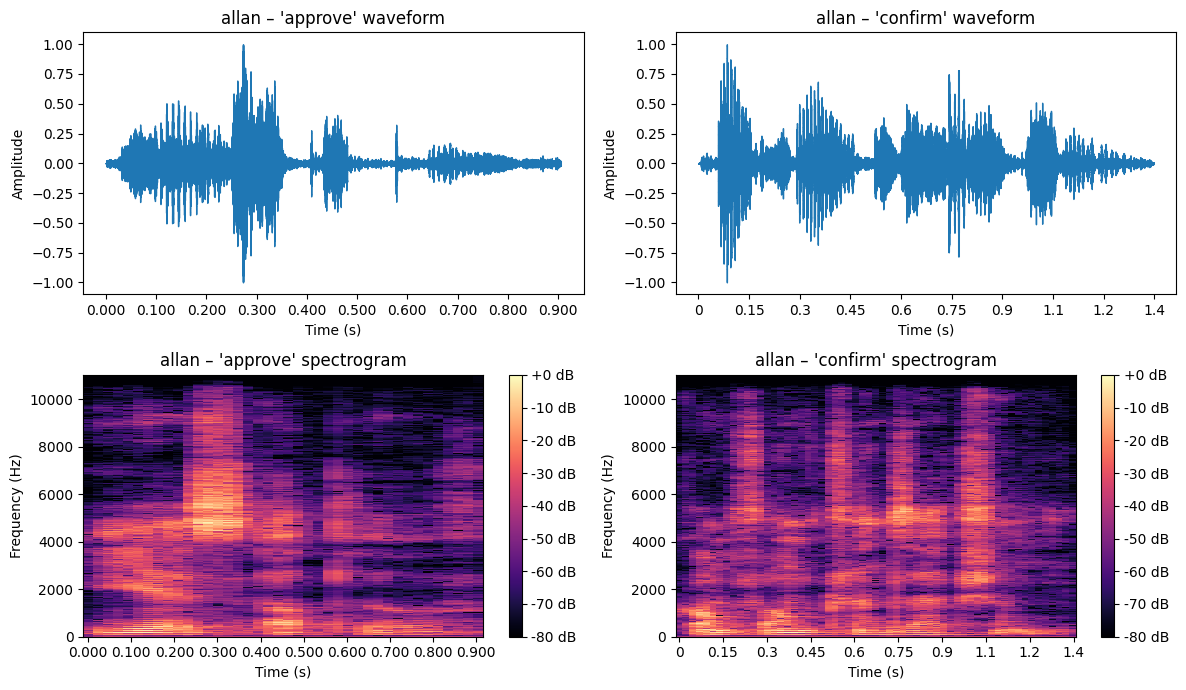

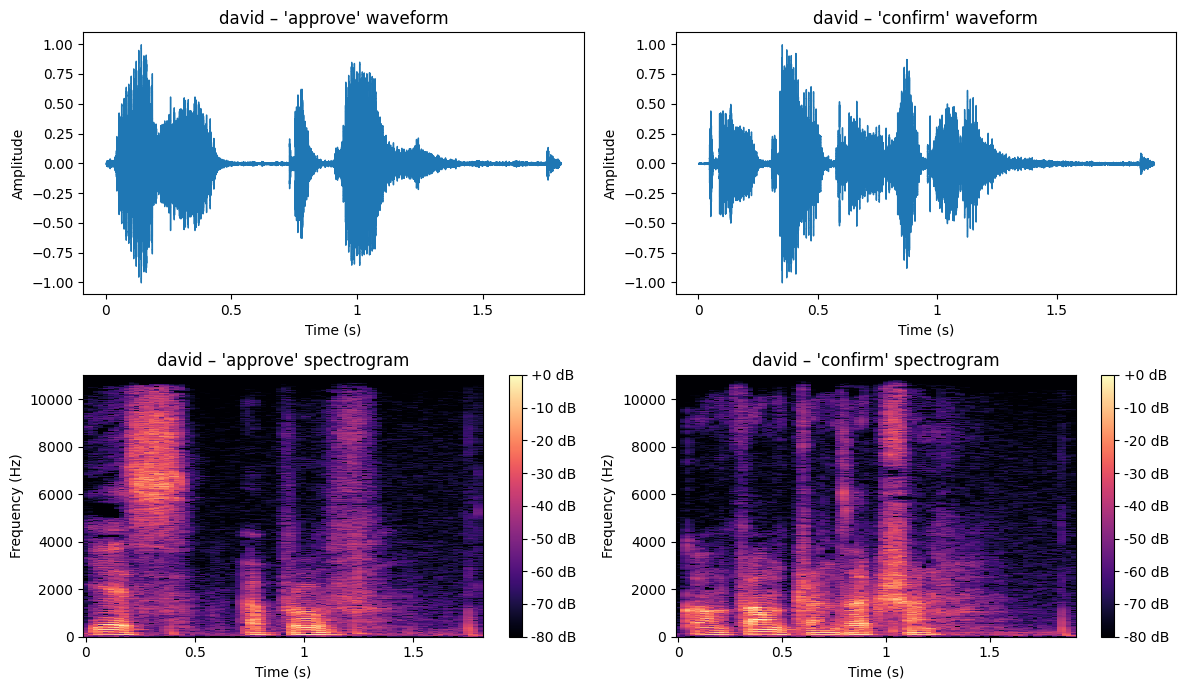

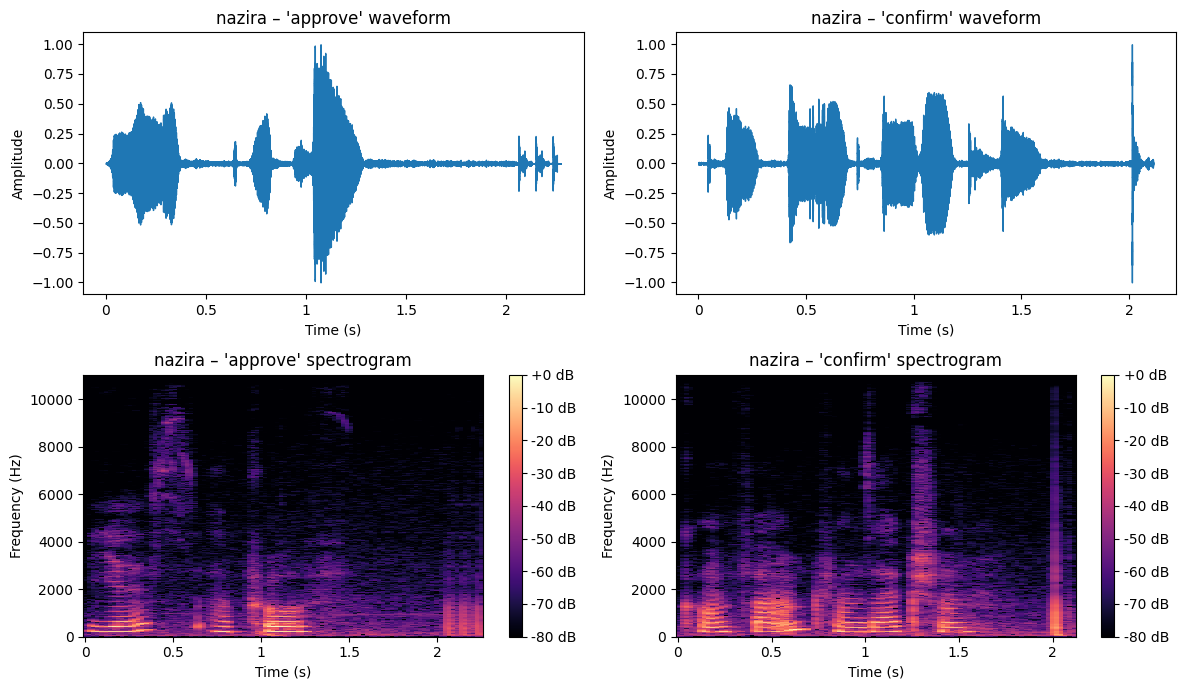

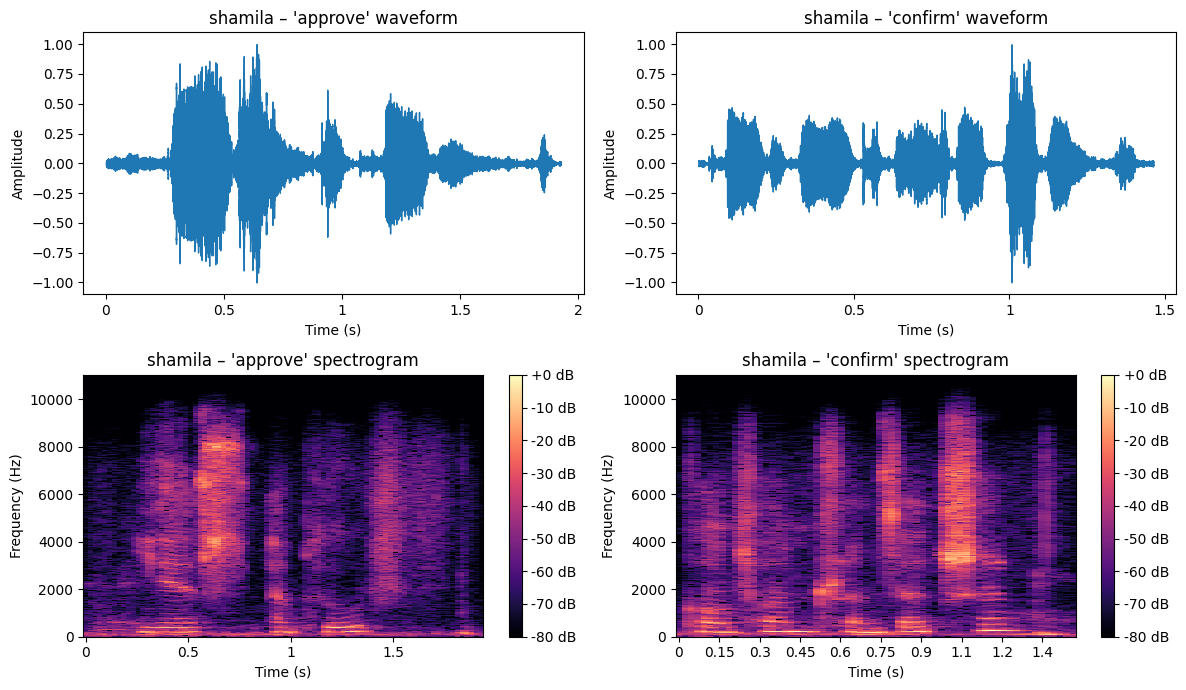

In [ ]:
for member, group in train_meta.groupby("member"):
    n = len(group)
    fig, axes = plt.subplots(2, n, figsize=(6 * n, 7), squeeze=False)
    for j, row in enumerate(group.itertuples()):
        y = audio[row.file]

        librosa.display.waveshow(y, sr=SR, ax=axes[0, j])
        axes[0, j].set(title=f"{member} – '{row.phrase}' waveform",
                       xlabel="Time (s)", ylabel="Amplitude")

        S_db = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
        img = librosa.display.specshow(S_db, sr=SR, x_axis="time", y_axis="hz", ax=axes[1, j])
        axes[1, j].set(title=f"{member} – '{row.phrase}' spectrogram",
                       xlabel="Time (s)", ylabel="Frequency (Hz)")
        fig.colorbar(img, ax=axes[1, j], format="%+2.0f dB")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{member}_waveform_spectrogram.png"), dpi=120)
    plt.show()

### Interpretation

**Allan:** Both recordings are clear, with speech well above the background noise. In *"Yes, approve"* (0.9 s), the loudest burst at about 0.3 s shows energy up to ~10 kHz in the spectrogram, which is typical of the "s" in "Yes"; "approve" is quieter, with energy mostly below 2 kHz. *"Confirm transaction"* (1.4 s) shows about five distinct bursts matching its syllables, with high-frequency stripes from consonants such as "f", "s" and "sh", and harmonic bands below 2 kHz during the vowels. Allan speaks quickly, with short pauses between syllables.

**David:** Clear recordings with low background noise. *"Yes, approve"* (1.8 s) starts with a strong burst where the "s" of "Yes" (0.2–0.45 s) shows the brightest high-frequency energy of the group, reaching ~10 kHz. A long silent pause follows before "approve", whose energy stays mostly below 2 kHz. *"Confirm transaction"* (1.9 s) shows several syllable bursts, with a strong high-frequency stripe at about 1.05 s from the "s"/"sh" consonants and clear low-frequency harmonics during the vowels.

**Nazira:** The cleanest recordings, with almost no background noise between words. Most energy is concentrated below ~1.5 kHz, with clear horizontal harmonic lines at the bottom of the spectrogram, and relatively little high-frequency energy apart from short consonant stripes. Nazira speaks the slowest (2.1–2.3 s), with distinct pauses between syllables. Both recordings end with a short, sharp spike (e.g. at ~2.05 s in *"Confirm transaction"*), most likely the click of stopping the recorder.

**Shamila:** Clear recordings with low noise. Compared to the others, her energy is spread further into the mid and high frequencies (about 2–8 kHz) throughout her speech, giving a "brighter" voice profile. In *"Yes, approve"* (1.9 s) the strongest burst at ~0.6 s reaches ~10 kHz (the "s" of "Yes"). *"Confirm transaction"* (1.5 s) shows about six syllable bursts, with the loudest at ~1.0 s, again with strong high-frequency energy. A small click appears at the end of the "approve" recording.

### Comparison across members
The four voices differ clearly. Nazira's energy is concentrated in the low frequencies, Shamila's extends furthest into the mid–high range, David has the strongest sibilant ("s") sounds, and Allan speaks fastest (0.9–1.4 s) and has slightly more background noise. Speaking speed also varies, from Allan (fastest) to Nazira (slowest). These differences in frequency distribution and timing are what the MFCC and spectral roll-off features will capture, which suggests the voiceprint model should be able to tell the members apart.

## 4. Augmentation
Each member's recording gets 6 augmented versions:
- **Pitch shift** up and down by 1 semitone, simulating natural changes in voice pitch
- **Time stretch** slower (0.9×) and faster (1.1×), simulating different speaking speeds
- **Background noise** at a low and a high level, simulating different recording environments

This increases the training data from 2 to 14 samples per member and helps the model recognize a voice even when it sounds slightly different. The unknown recordings are not augmented, because they are only used for testing.

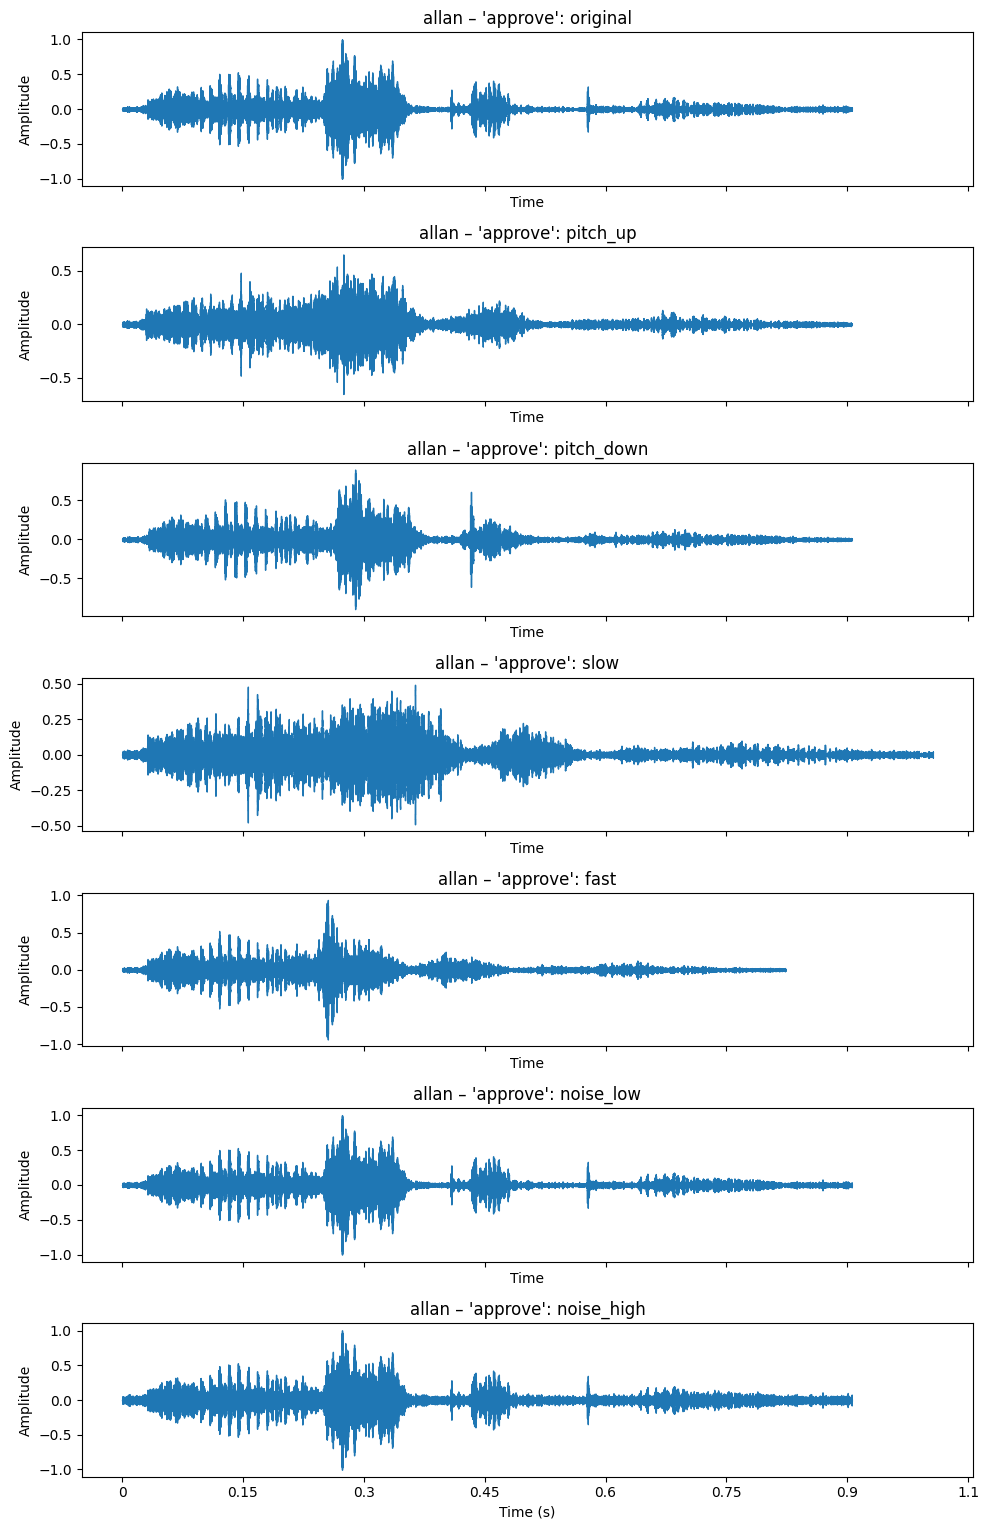

original


pitch_up


pitch_down


slow


fast


noise_low


noise_high


In [ ]:
def augment(y, sr=SR):
    noise = np.random.randn(len(y))
    return {
        "pitch_up":   librosa.effects.pitch_shift(y, sr=sr, n_steps=1),
        "pitch_down": librosa.effects.pitch_shift(y, sr=sr, n_steps=-1),
        "slow":       librosa.effects.time_stretch(y, rate=0.9),
        "fast":       librosa.effects.time_stretch(y, rate=1.1),
        "noise_low":  y + 0.005 * noise,
        "noise_high": y + 0.02 * noise,
    }

# Show the augmentations for one example recording
example = train_meta.iloc[0]
y0 = audio[example.file]
versions = {"original": y0, **augment(y0)}

fig, axes = plt.subplots(len(versions), 1, figsize=(10, 2.2 * len(versions)), sharex=True)
for ax, (name, y_v) in zip(axes, versions.items()):
    librosa.display.waveshow(y_v, sr=SR, ax=ax)
    ax.set(title=f"{example.member} – '{example.phrase}': {name}", ylabel="Amplitude")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "augmentation_examples.png"), dpi=120)
plt.show()

for name, y_v in versions.items():
    print(name)
    ipd.display(ipd.Audio(y_v, rate=SR))

**Observations:** Pitch shifting keeps the recording length the same (0.9 s) but changes the shape of the waveform peaks. Time stretching changes the duration: the slow version lasts about 1.0 s and the fast version about 0.82 s. Low noise is barely visible, while high noise makes the quiet parts between words visibly thicker, simulating a noisier recording environment. In every version the overall pattern of the phrase stays recognizable, so the speaker's identity is preserved while the model gets more varied training examples.

## 5. Feature extraction → `audio_features.csv`
For every recording (original + 6 augmented versions) we extract:
- **13 MFCCs** (mean and standard deviation): describe the shape of the vocal tract, the standard feature for identifying a speaker
- **Spectral roll-off**: the frequency below which 85% of the energy lies (how "bright" the voice is)
- **Spectral centroid**: the "center of mass" of the frequencies
- **RMS energy** (mean and standard deviation): loudness and how much it varies
- **Zero-crossing rate**: how noisy or breathy the sound is

In [ ]:
N_MFCC = 13

def extract_features(y, sr=SR):
    feats = {}
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC)
    for i in range(N_MFCC):
        feats[f"mfcc_{i+1}_mean"] = float(mfcc[i].mean())
        feats[f"mfcc_{i+1}_std"] = float(mfcc[i].std())
    feats["spectral_rolloff"] = float(librosa.feature.spectral_rolloff(y=y, sr=sr).mean())
    feats["spectral_centroid"] = float(librosa.feature.spectral_centroid(y=y, sr=sr).mean())
    rms = librosa.feature.rms(y=y)
    feats["rms_energy_mean"] = float(rms.mean())
    feats["rms_energy_std"] = float(rms.std())
    feats["zero_crossing_rate"] = float(librosa.feature.zero_crossing_rate(y).mean())
    return feats

rows = []
for row in meta.itertuples():
    y = audio[row.file]
    versions = {"original": y}
    if row.member not in UNAUTHORIZED_NAMES:      # only augment the members' recordings
        versions.update(augment(y))
    for aug_name, y_v in versions.items():
        rows.append({"file": os.path.basename(row.file), "member": row.member,
                     "phrase": row.phrase, "augmentation": aug_name,
                     **extract_features(y_v)})

features_df = pd.DataFrame(rows)
features_df.to_csv(os.path.join(OUTPUT_DIR, "audio_features.csv"), index=False)
print("Saved audio_features.csv with shape", features_df.shape)
features_df.head()

Saved audio_features.csv with shape (58, 35)


,file,member,phrase,augmentation,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,...,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,spectral_rolloff,spectral_centroid,rms_energy_mean,rms_energy_std,zero_crossing_rate
0,Allan_approve.wav,allan,approve,original,-217.402832,72.960426,80.365196,53.669952,17.778984,29.389347,...,16.233459,19.074478,14.152246,-15.822474,7.982017,5085.873413,2751.411396,0.085462,0.060762,0.176135
1,Allan_approve.wav,allan,approve,pitch_up,-238.458298,71.818260,73.625984,50.758808,22.959192,26.528900,...,16.389072,6.462160,13.100036,-17.804043,8.457155,5413.985596,2950.906666,0.063198,0.048181,0.199316
2,Allan_approve.wav,allan,approve,pitch_down,-236.442169,76.895798,87.371666,50.054546,6.778249,27.555151,...,15.305140,24.991512,11.937582,-12.599637,12.922649,4763.682861,2572.909298,0.076877,0.056624,0.161475
3,Allan_approve.wav,allan,approve,slow,-242.750870,70.293495,77.205544,52.490540,17.978859,27.152800,...,16.848780,18.038673,13.654008,-16.975313,7.320671,5096.028276,2779.116680,0.061382,0.043989,0.183871
4,Allan_approve.wav,allan,approve,fast,-233.664871,74.764725,78.502541,51.102566,18.380539,27.956057,...,16.753935,19.541443,14.074121,-14.218298,7.264693,5113.537598,2771.656920,0.069836,0.051236,0.180868


### Comparing features across members

,mfcc_1_mean,mfcc_2_mean,spectral_rolloff,spectral_centroid,rms_energy_mean
member,,,,,
allan,-186.44,70.46,5555.06,2963.92,0.09
david,-208.48,105.88,4781.18,2493.99,0.09
nazira,-260.31,133.03,3630.59,1877.33,0.08
shamila,-218.11,51.16,5609.61,2841.28,0.10


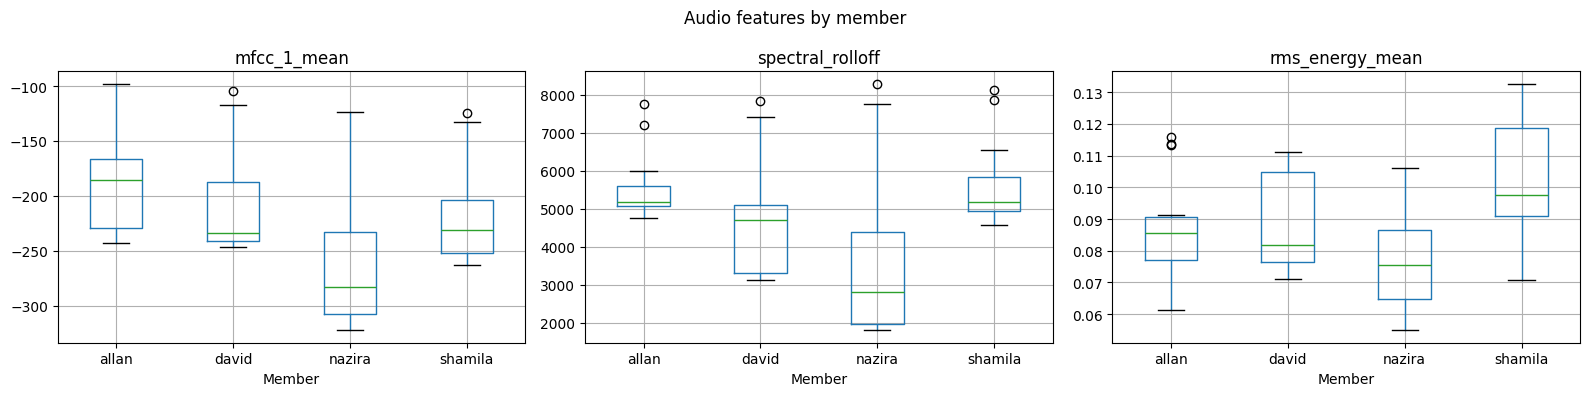

In [ ]:
summary_cols = ["mfcc_1_mean", "mfcc_2_mean", "spectral_rolloff", "spectral_centroid", "rms_energy_mean"]
known_df = features_df[~features_df.member.isin(UNAUTHORIZED_NAMES)]
display(known_df.groupby("member")[summary_cols].mean().round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["mfcc_1_mean", "spectral_rolloff", "rms_energy_mean"]):
    known_df.boxplot(column=col, by="member", ax=ax)
    ax.set(title=col, xlabel="Member")
plt.suptitle("Audio features by member")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "features_by_member.png"), dpi=120)
plt.show()

**Observations:** The features confirm the patterns seen in the spectrograms. Nazira has by far the lowest spectral roll-off (3,631 Hz) and centroid (1,877 Hz), reflecting a voice with energy concentrated in the low frequencies. Allan and Shamila have the highest roll-off (~5,560–5,610 Hz) and are similar on this feature, but they differ clearly in their MFCCs (e.g. mean MFCC-1 of −186 vs −218 and MFCC-2 of 70 vs 51). Shamila's recordings have the highest average energy and Nazira's the lowest. Because the box plots overlap, no single feature separates all four members on its own, which is why the model combines all 31 features.

## 6. Train the Voiceprint Verification Model
A **Random Forest** classifier, with feature scaling, learns to identify which member is speaking. The members' data is split into 75% for training and 25% for testing, keeping the same proportion of each member in both sets.

*Limitation:* augmented copies of the same recording can end up in both the training and test sets, so the test scores are likely optimistic. More original recordings per member would give a more realistic evaluation.

Accuracy : 1.000
Precision: 1.000
Recall   : 1.000
F1-score : 1.000
Log loss : 0.246

               precision    recall  f1-score   support

       allan       1.00      1.00      1.00         4
       david       1.00      1.00      1.00         3
      nazira       1.00      1.00      1.00         4
     shamila       1.00      1.00      1.00         3

    accuracy                           1.00        14
   macro avg       1.00      1.00      1.00        14
weighted avg       1.00      1.00      1.00        14



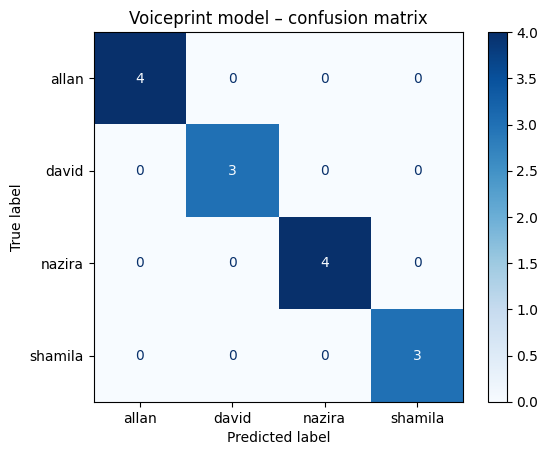

In [ ]:
feature_cols = [c for c in features_df.columns if c not in ["file", "member", "phrase", "augmentation"]]
X = known_df[feature_cols].values
y = known_df["member"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", RandomForestClassifier(n_estimators=200, random_state=42)),
])
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, average='macro', zero_division=0):.3f}")
print(f"Recall   : {recall_score(y_test, y_pred, average='macro', zero_division=0):.3f}")
print(f"F1-score : {f1_score(y_test, y_pred, average='macro'):.3f}")
print(f"Log loss : {log_loss(y_test, y_proba, labels=model.classes_):.3f}")
print("\n", classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Voiceprint model – confusion matrix")
plt.savefig(os.path.join(OUTPUT_DIR, "voice_confusion_matrix.png"), dpi=120)
plt.show()

**Results:** The model classified all 14 test samples correctly (accuracy, precision, recall and F1-score = 1.00), and the confusion matrix shows no confusion between members. The log loss of 0.246 shows the model was correct but not fully certain, assigning on average about 78% probability to the correct member. These scores are likely optimistic, because augmented versions of the same original recording can appear in both the training and test sets, and the test set is small (14 samples). A harder test is shown below.

### Harder test: recognizing voices on an unseen phrase
The model is trained only on the *"Yes, approve"* recordings (and their augmentations) and tested on *"Confirm transaction"*. This removes the overlap between training and test data and checks whether the model learned each person's voice rather than a specific recording.

Accuracy : 0.857
F1-score : 0.857
Log loss : 0.654


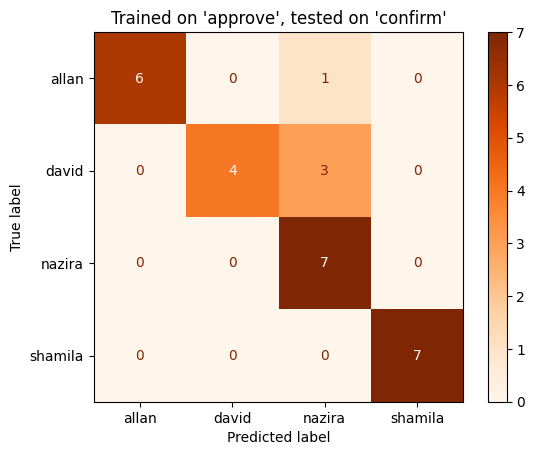

In [ ]:
train_mask = known_df["phrase"] == "approve"
X_tr, y_tr = known_df.loc[train_mask, feature_cols].values, known_df.loc[train_mask, "member"].values
X_te, y_te = known_df.loc[~train_mask, feature_cols].values, known_df.loc[~train_mask, "member"].values

phrase_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", RandomForestClassifier(n_estimators=200, random_state=42)),
])
phrase_model.fit(X_tr, y_tr)

p_pred = phrase_model.predict(X_te)
p_proba = phrase_model.predict_proba(X_te)

print(f"Accuracy : {accuracy_score(y_te, p_pred):.3f}")
print(f"F1-score : {f1_score(y_te, p_pred, average='macro'):.3f}")
print(f"Log loss : {log_loss(y_te, p_proba, labels=phrase_model.classes_):.3f}")

ConfusionMatrixDisplay.from_predictions(y_te, p_pred, cmap="Oranges")
plt.title("Trained on 'approve', tested on 'confirm'")
plt.savefig(os.path.join(OUTPUT_DIR, "voice_confusion_matrix_unseen_phrase.png"), dpi=120)
plt.show()

**Results:** On the unseen phrase the model reached 85.7% accuracy, an F1-score of 0.857 and a log loss of 0.654. This is lower than the standard test, as expected, but it shows that the model learned each member's voice rather than memorizing specific recordings. Nazira and Shamila were recognized perfectly (7/7), consistent with their very distinct frequency profiles. Most errors were David being predicted as Nazira (3/7), which matches the feature analysis: David has the second-lowest spectral roll-off and is therefore closest to Nazira's low-frequency voice. One of Allan's samples was also predicted as Nazira. More recordings per member, especially of different phrases, would likely reduce these errors.

## 7. Rejecting unauthorized voices (confidence threshold)
The model always picks one of the four members, even for a stranger. So a voice is only accepted when the model's confidence is above a **threshold**. Below, the final model is trained on all members' data, and the confidence for known members is compared with the confidence for the unknown recordings to choose a suitable threshold.

In [ ]:
# Final model: retrain on ALL members' data
model.fit(X, y)

def confidence_for(y_audio):
    feats = pd.DataFrame([extract_features(y_audio)])[feature_cols]
    probs = model.predict_proba(feats.values)[0]
    return model.classes_[np.argmax(probs)], float(np.max(probs))

print("Known members (original recordings):")
for row in train_meta.itertuples():
    who, conf = confidence_for(audio[row.file])
    print(f"  {os.path.basename(row.file):25s} → {who:8s} confidence {conf:.2f}")

print("\nUnknown recordings:")
for row in unauth_meta.itertuples():
    who, conf = confidence_for(audio[row.file])
    print(f"  {os.path.basename(row.file):25s} → closest: {who:8s} confidence {conf:.2f}")

Known members (original recordings):
  Allan_approve.wav         → allan    confidence 0.98
  Allan_confirm.wav         → allan    confidence 0.97
  David_approve.wav         → david    confidence 0.96
  David_confirm.wav         → david    confidence 0.97
  Nazira_approve.wav        → nazira   confidence 0.97
  Nazira_confirm.wav        → nazira   confidence 0.97
  Shamila_approve.wav       → shamila  confidence 0.98
  Shamila_confirm.wav       → shamila  confidence 0.99

Unknown recordings:
  unknown_approve.wav       → closest: david    confidence 0.41
  unknown_confirm.wav       → closest: david    confidence 0.47


**Choosing the threshold:** The members' original recordings receive 0.96–0.99 confidence, while the unknown speaker's recordings only reach 0.41–0.47. Because the members' recordings were part of the training data, their confidences are inflated; new recordings will score lower. A threshold of **0.6** sits clearly above the unknown speaker while leaving a margin so that new recordings from real members are still accepted.

In [ ]:
THRESHOLD = 0.6

def verify_voice(audio_path, threshold=THRESHOLD):
    y_audio = load_audio(audio_path)
    feats = pd.DataFrame([extract_features(y_audio)])[feature_cols]
    probs = model.predict_proba(feats.values)[0]
    best = int(np.argmax(probs))
    confidence = float(probs[best])
    verified = confidence >= threshold
    return {"identity": model.classes_[best] if verified else "unknown",
            "verified": verified,
            "confidence": round(confidence, 3)}

print("Authorized attempts:")
for row in train_meta.groupby("member").head(1).itertuples():
    result = verify_voice(row.file)
    status = "✅ ACCESS GRANTED" if result["verified"] else "❌ ACCESS DENIED"
    print(f"  {os.path.basename(row.file):25s} → {status}  {result}")

print("\nUnauthorized attempts:")
for row in unauth_meta.itertuples():
    result = verify_voice(row.file)
    status = "✅ ACCESS GRANTED" if result["verified"] else "❌ ACCESS DENIED"
    print(f"  {os.path.basename(row.file):25s} → {status}  {result}")

Authorized attempts:
  Allan_approve.wav         → ✅ ACCESS GRANTED  {'identity': 'allan', 'verified': True, 'confidence': 0.985}
  David_approve.wav         → ✅ ACCESS GRANTED  {'identity': 'david', 'verified': True, 'confidence': 0.965}
  Nazira_approve.wav        → ✅ ACCESS GRANTED  {'identity': 'nazira', 'verified': True, 'confidence': 0.97}
  Shamila_approve.wav       → ✅ ACCESS GRANTED  {'identity': 'shamila', 'verified': True, 'confidence': 0.985}

Unauthorized attempts:
  unknown_approve.wav       → ❌ ACCESS DENIED  {'identity': 'unknown', 'verified': False, 'confidence': 0.41}
  unknown_confirm.wav       → ❌ ACCESS DENIED  {'identity': 'unknown', 'verified': False, 'confidence': 0.475}


**Verification test:** All four members were accepted with 0.965–0.985 confidence, and both unknown recordings were rejected (0.41 and 0.475, below the 0.6 threshold). The voiceprint model therefore correctly separates authorized members from an unauthorized speaker.

## 8. Save the model for integration

In [ ]:
joblib.dump({"model": model, "feature_cols": feature_cols, "threshold": THRESHOLD, "sr": SR},
            os.path.join(OUTPUT_DIR, "voice_model.pkl"))
print("Saved voice_model.pkl to", OUTPUT_DIR)
print("Files in output folder:", sorted(os.listdir(OUTPUT_DIR)))

Saved voice_model.pkl to /content/drive/MyDrive/audio_outputs
Files in output folder: ['allan_waveform_spectrogram.png', 'audio_features.csv', 'augmentation_examples.png', 'david_waveform_spectrogram.png', 'features_by_member.png', 'nazira_waveform_spectrogram.png', 'shamila_waveform_spectrogram.png', 'voice_confusion_matrix.png', 'voice_confusion_matrix_unseen_phrase.png', 'voice_model.pkl']
